Importing the necessary libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

importing the dataset

In [ ]:
dr= pd.read_csv('water_potability.csv');
dr.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


shape of the dataset, shows 3276 rows and 10 colunms

In [ ]:
print('shape of the dataset=' , dr.shape)

shape of the dataset= (3276, 10)


In [ ]:
dr.columns.values.tolist()

['ph',
 'Hardness',
 'Solids',
 'Chloramines',
 'Sulfate',
 'Conductivity',
 'Organic_carbon',
 'Trihalomethanes',
 'Turbidity',
 'Potability']

In [ ]:
dr.describe().style.background_gradient(cmap='Blues')

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


In [ ]:
print(dr.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB
None


In [ ]:
dr.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

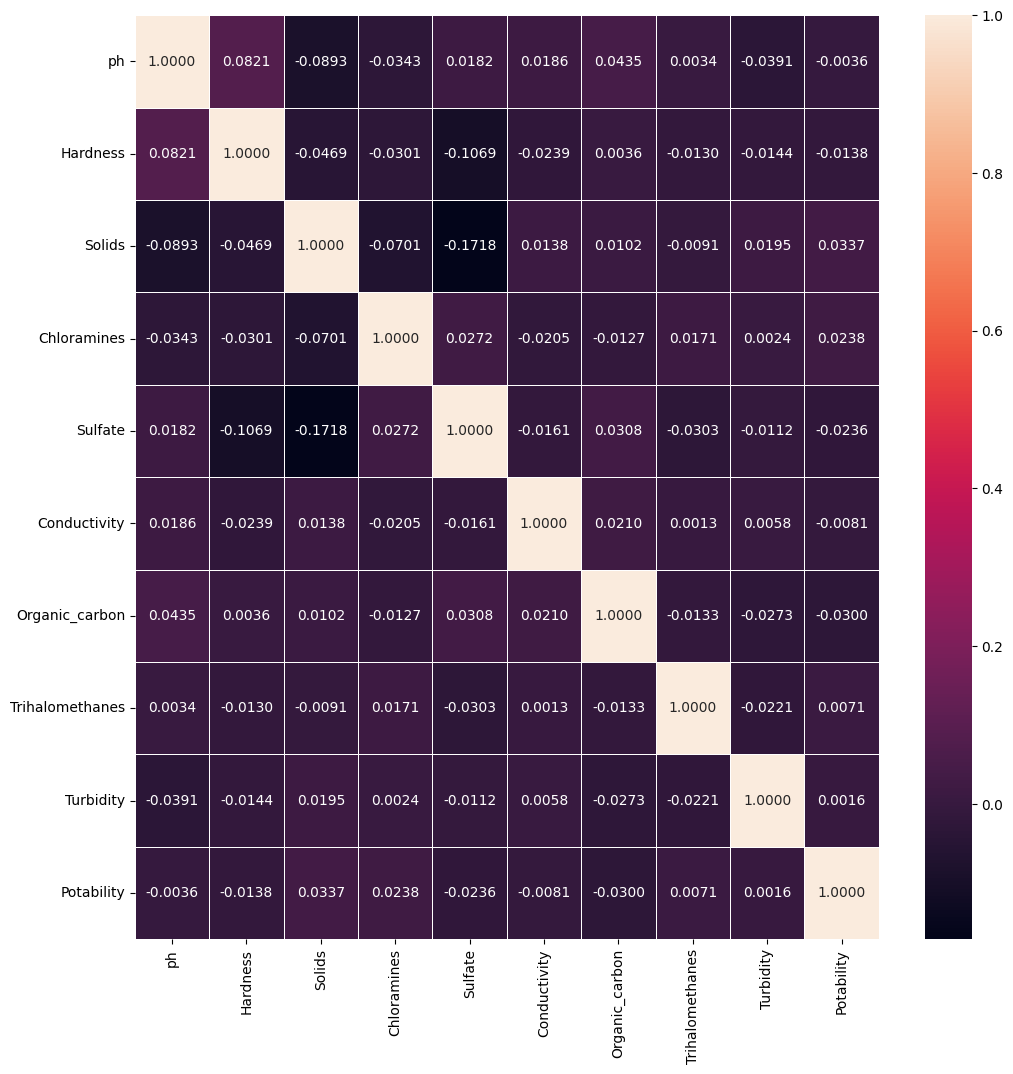

In [ ]:
dr.corr()
f, ax= plt.subplots(figsize=(12, 12))
sns.heatmap(dr.corr(), annot=True, linewidths=0.5, fmt="0.4f", ax=ax)
plt.show()

now we handle the missing values or Nan values

In [ ]:
dd=dr.dropna()
dd.isnull().sum()

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

In [ ]:
print('Dataset before dropping missing values=', dr.shape)
print('Dataset after dropping missing values=' , dd.shape)

Dataset before dropping missing values= (3276, 10)
Dataset after dropping missing values= (2011, 10)


In [ ]:
print('Data lost= ', (dr.shape[0]-dd.shape[0])/dr.shape[0]*100,'%')

Data lost=  38.614163614163616 %


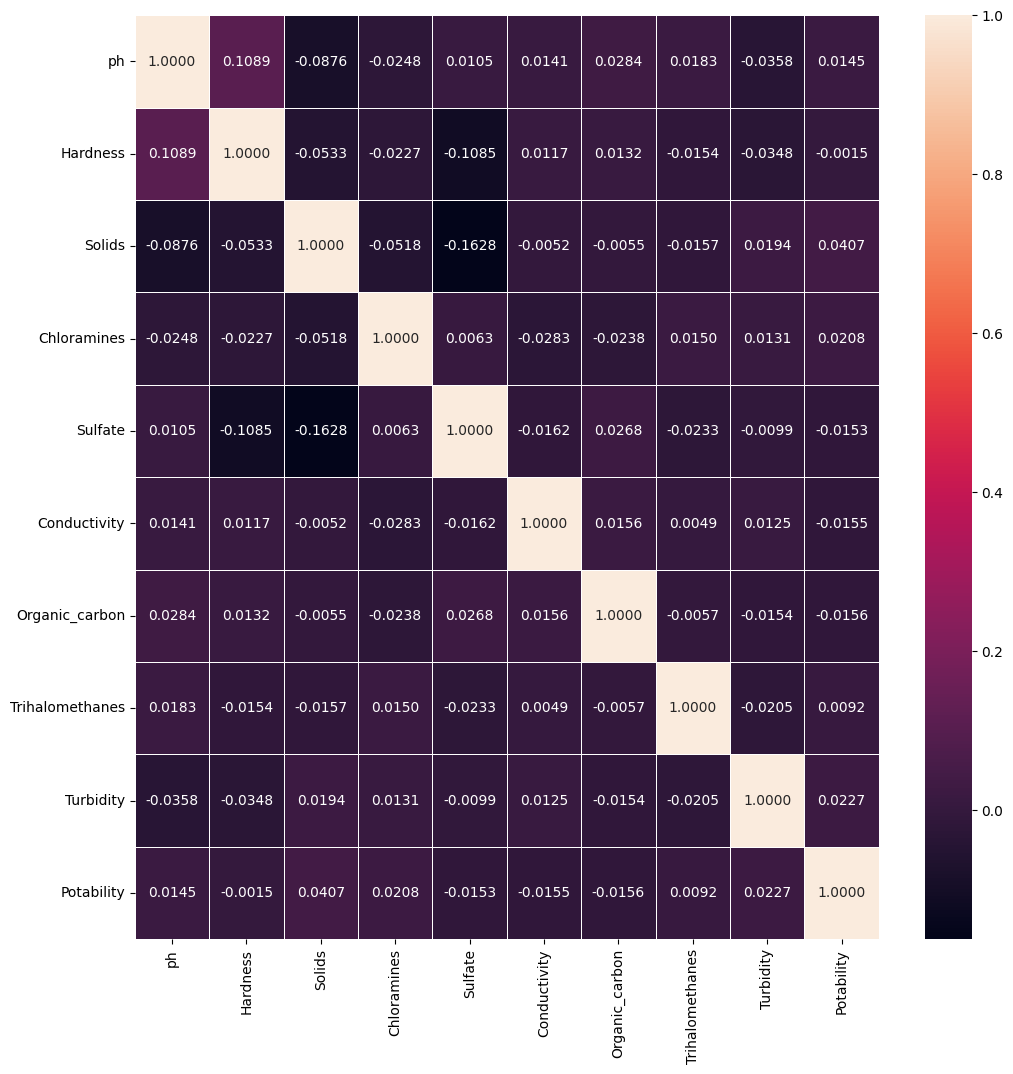

In [ ]:
dd.corr()
f, ax= plt.subplots(figsize=(12, 12))
sns.heatmap(dd.corr(), annot=True, linewidths=0.5, fmt="0.4f", ax=ax)
plt.show()

lets check whether the data is balanced or not

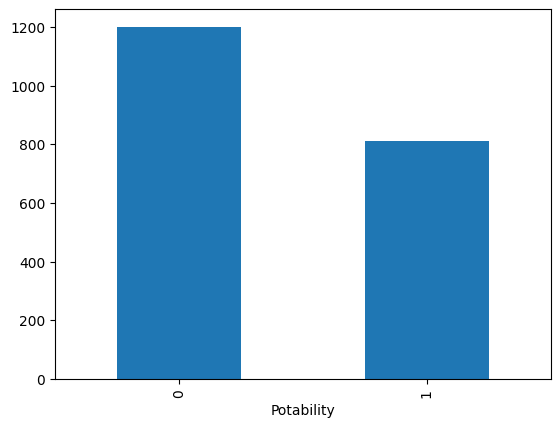

In [ ]:
dd.Potability.value_counts().plot(kind='bar')
plt.show()

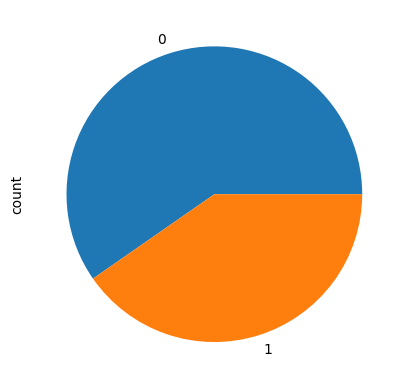

In [ ]:
dd.Potability.value_counts().plot(kind='pie')
plt.show()

balancing now the data

In [ ]:
first= dd[dd.Potability==1]
second= dd[dd.Potability==0]
from sklearn.utils import resample
dd= resample(first, replace=True, n_samples=len(second), random_state=42)
dd= pd.concat([dd, second])
from sklearn.utils import shuffle
dd= shuffle(dd) # shuffling so that there is particular sequence


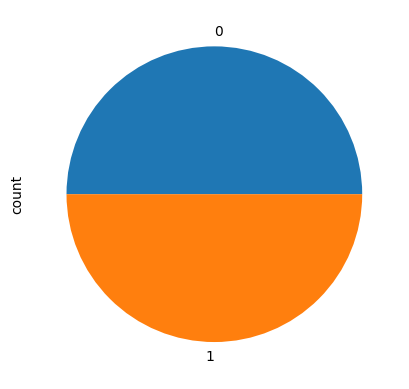

In [ ]:
dd.Potability.value_counts().plot(kind='pie')
plt.show()

great now balanced

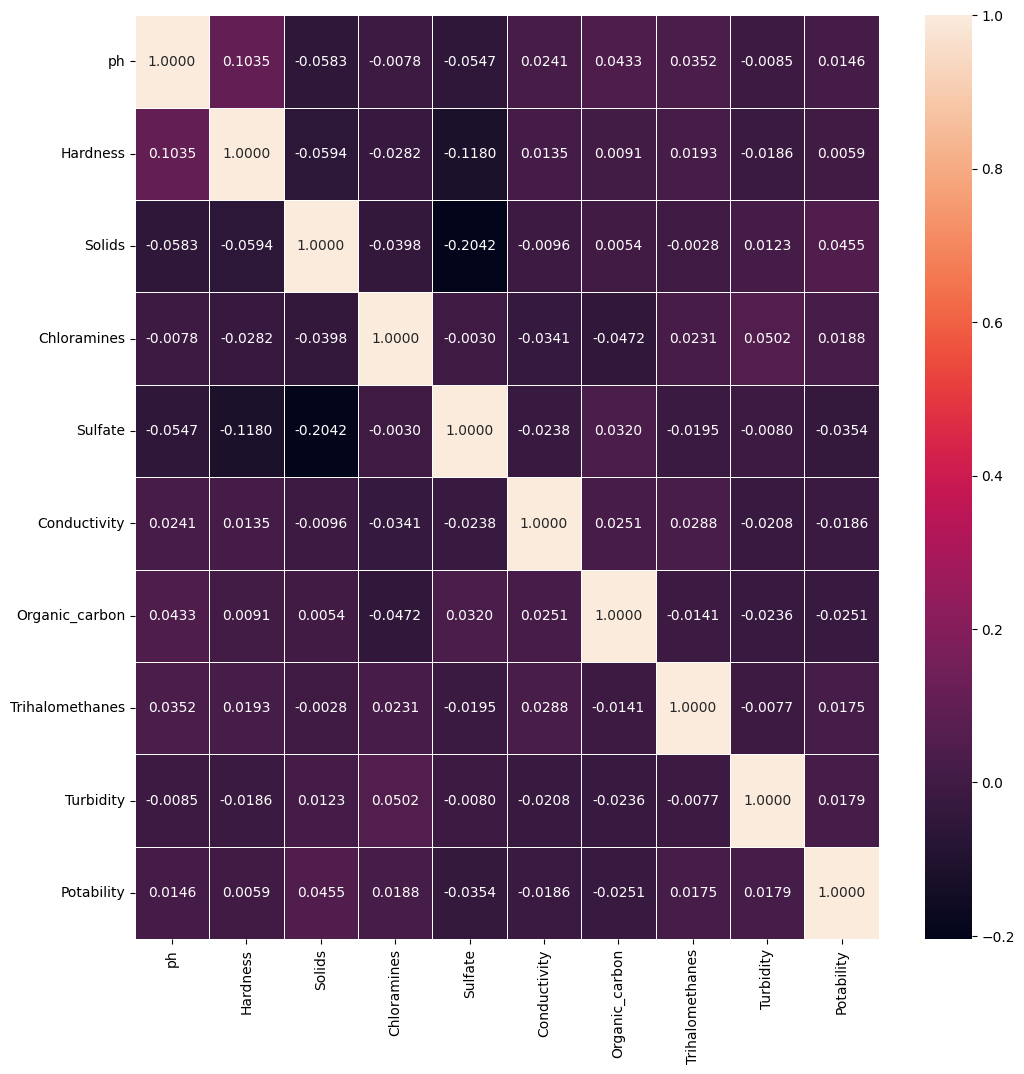

In [ ]:
dd.corr()
f, ax= plt.subplots(figsize=(12, 12))
sns.heatmap(dd.corr(), annot=True, linewidths=0.5, fmt="0.4f", ax=ax)
plt.show()

In [ ]:
x= dd .iloc[: , :-1].values #-1 is to separate the last index from matrix of features
y= dd .iloc[: , -1].values # for the dependent variable

Normalization

In [ ]:
from sklearn.preprocessing import StandardScaler
sc= StandardScaler()
x= sc.fit_transform(x)


now we build the models first by splitting train and test set, then by hyperparameter tunning , then we train them

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import GridSearchCV,  RandomizedSearchCV
from sklearn.model_selection import train_test_split




In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)

Hyperparameter tunning

In [ ]:

RF= RandomForestClassifier(random_state=42)
DT= DecisionTreeClassifier()
KNN= KNeighborsClassifier()
XGB= XGBClassifier(eval_metric= 'logloss', use_label_encoder= False)
SVM= SVC()
NB= GaussianNB()

Ada= AdaBoostClassifier(random_state=42)



#RandomForestClassifier
param_grid = {'n_estimators': [100,200,350,500], 'min_samples_leaf': [2,10,30]}
grid_RF = GridSearchCV(estimator=RF, param_grid=param_grid, cv=5, scoring =
                       'accuracy')


#DecisionTreeClassifier
param_grid = {'criterion': ['gini', 'entropy'],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]}
grid_DT = GridSearchCV(estimator=DT, param_grid=param_grid, cv=5, scoring =
                       'accuracy')


#KNeighborsClassifier
param_grid = {
    'n_neighbors': [3, 5, 7, 9],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}
grid_KNN = GridSearchCV(estimator=KNN, param_grid=param_grid, cv=5, scoring =
                       'accuracy')



#XGBClassifier
param_grid= {'n_estimators': [50,100,250,400,500,600,800,1000],
             'learning_rate': [0.2, 0.5, 0.8, 1]}
grid_XGB = GridSearchCV(estimator=XGB, param_grid=param_grid, cv=5, scoring =
                       'accuracy')



#SVM
param_grid = {'C': [0.1,1,10,100],
              'kernel': ['Linear', 'rbf', 'Poly', 'Sigmoid'],
              'gamma': ['scale', 'auto']}
grid_SVM = GridSearchCV(estimator=SVM, param_grid=param_grid, cv=5, scoring =
                       'accuracy')



#Naivebayes
param_grid = {'var_smoothing': np.logspace(0, -9, num=100)}
grid_NB = GridSearchCV(estimator=NB, param_grid=param_grid, cv=5, scoring =
                       'accuracy')




#AdaBoostClassifier
param_grid= {'n_estimators': [50,100,250,400,500,600],
             'learning_rate': [0.2, 0.5, 0.8, 1]}
grid_Ada = GridSearchCV(estimator=Ada, param_grid=param_grid, cv=5, scoring =
                       'accuracy')


In [ ]:

grid_RF.fit(x_train, y_train)
grid_DT.fit(x_train, y_train)
grid_KNN.fit(x_train, y_train)
grid_XGB.fit(x_train, y_train)
grid_SVM.fit(x_train, y_train)
grid_NB.fit(x_train, y_train)
grid_Ada.fit(x_train, y_train)

print("Best parameters for RF:" , grid_RF.best_params_)
print("Best parameters for DT:" , grid_DT.best_params_)
print("Best parameters for KNN:" , grid_KNN.best_params_)
print("Best parameters for XGB:" , grid_XGB.best_params_)
print("Best parameters for SVM:" , grid_SVM.best_params_)
print("Best parameters for NB:" , grid_NB.best_params_)
print("Best parameters for Ada:" , grid_Ada.best_params_)


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py:378: FitFailedWarning: 
120 fits failed out of a total of 160.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
40 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_validation.py", line 686, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.10/dist-packages/sklearn/svm/_base.py", line 180, in fit
    self._validate_params()
  File "/usr/local/lib/python3.10/dist-packages/sklearn/base.py", line 600, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.10/dist-packages/sklearn/utils/_par

Best parameters for RF: {'min_samples_leaf': 2, 'n_estimators': 200}
Best parameters for DT: {'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best parameters for KNN: {'metric': 'manhattan', 'n_neighbors': 5, 'weights': 'distance'}
Best parameters for XGB: {'learning_rate': 0.2, 'n_estimators': 100}
Best parameters for SVM: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best parameters for NB: {'var_smoothing': 0.15199110829529336}
Best parameters for Ada: {'learning_rate': 1, 'n_estimators': 600}


wasnt able to hyperparemeter tunning for LR AND MLP

In [ ]:
MLP= MLPClassifier(random_state=42, max_iter=300)
MLP.fit(x_train,y_train)
y_pred= MLP.predict(x_test)
MLP_accuracy = accuracy_score(y_test,y_pred)


LR= LogisticRegression(random_state=42)
LR.fit(x_train,y_train)
yy_pred= LR.predict(x_test)
LR_accuracy= accuracy_score(y_test,yy_pred)


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
classifiers= [ ('K Nearest Neighbours', KNN),
               ('Decision Tree', DT), ('Random Forest', RF), ('AdaBoost', Ada),
              ('XGBoost', XGB) , ('SVM', SVM), ('Naive Bayes', NB), ('Logistic Regression', LR), ('MLP', MLP)]


from sklearn.metrics import accuracy_score

for classifier_name, classifier in classifiers:
    classifier.fit(x_train, y_train)

    y_pred = classifier.predict(x_test)
    accuracy= accuracy_score(y_test,y_pred)

    print('{:s}: {:.2f}'.format(classifier_name, accuracy))

K Nearest Neighbours: 0.66
Decision Tree: 0.75
Random Forest: 0.81
AdaBoost: 0.60
XGBoost: 0.80
SVM: 0.69
Naive Bayes: 0.57
Logistic Regression: 0.49
MLP: 0.73


/usr/local/lib/python3.10/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:686: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
